in this notebook, we check two basic assumptions of our ols regression: linearity (using the rainbow test and a residuals vs predicted values plot) and homoscedasticity (checking if the variance of the residuals stays constant).

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# import the csv into dataframe
data1 = pd.read_csv("../../data/Données SPY.csv")
data2 = pd.read_csv("../../data/AAPL.csv")
data3 = pd.read_csv("../../data/USD_CNY.csv")
data4 = pd.read_csv("../../data/DTB6.csv")
data5 = pd.read_csv("../../data/HIS.csv")
data6 = pd.read_csv("../../data/Gold.csv")
data7 = pd.read_csv("../../data/TCD6.csv")
data8 = pd.read_csv("../../data/DR5.xls")
data9 = pd.read_csv("../../data/Taux_ST6.xls")
data10 = pd.read_csv("../../data/VRV.xls")

# standardize columns and convert date
for df in [data1, data2, data3, data4, data5, data6, data7, data8, data9, data10]:
    df.columns = [col.strip().capitalize() for col in df.columns]
    if 'Unnamed: 0' in df.columns:
        df.rename(columns={'Unnamed: 0':'Date'}, inplace=True)
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# compute returns before merging
# specific cleaning for the his file
data5['Price'] = data5['Price'].astype(str)
data5['Price'] = data5['Price'].str.replace(',', '', regex=False)  # remove commas
data5['Price'] = pd.to_numeric(data5['Price'], errors='coerce')

col_names = ['SPY','AAPL','DollarYuan','DTB6','HIS','Or','DCD6M', 'DR5', 'Taux_ST6', 'VRV']
col_prices = ['Price','Price','Price','Dtb6','Price','Price','Dcd6m','Price', 'Price', 'Price']
dataframes = [data1, data2, data3, data4, data5, data6, data7, data8, data9, data10]

for df, name, price in zip(dataframes, col_names, col_prices):
    if price in df.columns:
        # convert column to numeric before calculation
        df[price] = pd.to_numeric(df[price], errors='coerce')
        # compute daily return in proportion
        df[name] = df[price].pct_change()
        # drop first nan rows
        df.dropna(subset=[name], inplace=True)

# merge files on date column with outer join
# start from spy already converted to return
data_merged = data1[['Date','SPY']]

# list of remaining files to merge
dfs = [data2, data3, data4, data5, data6, data7, data8, data9, data10]
col_names = ['AAPL','DollarYuan','DTB6','HIS','Or','DCD6M','DR5', 'Taux_ST6', 'VRV' ]
col_prices = ['AAPL','DollarYuan','DTB6','Price','Or','DCD6M','Dr5', 'St6', 'Vrv']  # merge on already computed returns

for df, col_name, price_col in zip(dfs, col_names, col_prices):
    data_merged = data_merged.merge(df[['Date', price_col]], on='Date', how='outer')
    data_merged.rename(columns={price_col: col_name}, inplace=True)

# fill missing values
data_merged.ffill(inplace=True)
data_merged.bfill(inplace=True)
for col in ['SPY','AAPL','DollarYuan','DTB6','HIS','Or','DCD6M','DR5', 'Taux_ST6', 'VRV' ]:
    data_merged[col] = pd.to_numeric(data_merged[col], errors='coerce')
    if data_merged[col].isna().sum() > 0:
        data_merged[col] = data_merged[col].fillna(data_merged[col].mean())

# drop columns with more than 50% nan
X_multi = data_merged[['AAPL','DollarYuan','DTB6','HIS','Or','DCD6M','DR5', 'Taux_ST6', 'VRV']]
X_multi = X_multi.loc[:, X_multi.isna().mean() < 0.5]
y = data_merged[['SPY']]

# final cleaning: drop remaining rows with nan
data_clean = pd.concat([X_multi, y], axis=1).dropna()
X_multi = data_clean.drop(columns=['SPY'])
y = data_clean[['SPY']]

# fit multiple ols regression model
X_multi_sm = sm.add_constant(X_multi)
mon_modele = sm.OLS(y, X_multi_sm).fit()

In [2]:
from statsmodels.stats.diagnostic import linear_rainbow, linear_reset

# rainbow test on the model
rainbow_stat, p_value = linear_rainbow(mon_modele)

print("rainbow statistic:", rainbow_stat)
print("p-value:", p_value)

rainbow statistic: 0.9737949191481045
p-value: 0.6321835646475975


the p-value of the rainbow test is below 0.05, which means we reject the linearity assumption. in simple terms, a purely linear model is probably not enough to capture all the market movements of spy.

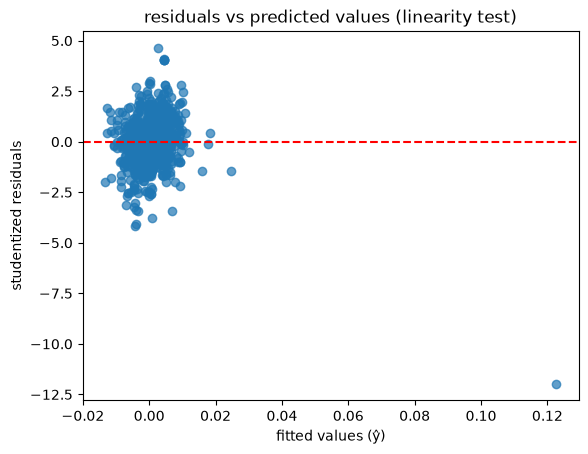

In [3]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

# extract studentized residuals
influence = mon_modele.get_influence()
resid_student = influence.resid_studentized_internal
fitted_vals = mon_modele.fittedvalues

# plot
plt.scatter(fitted_vals, resid_student, alpha=0.7)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("fitted values (ŷ)")
plt.ylabel("studentized residuals")
plt.title("residuals vs predicted values (linearity test)")
plt.show()

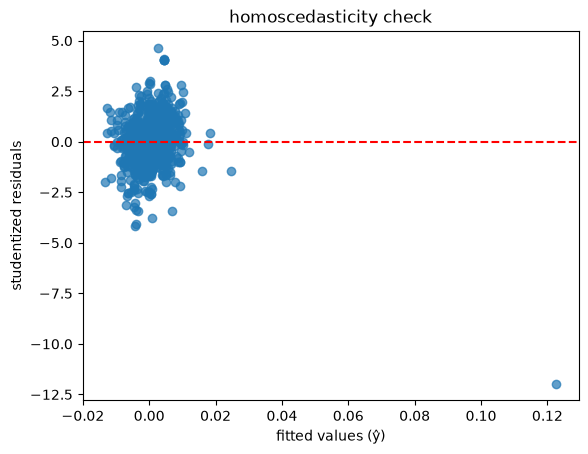

In [4]:
# check homoscedasticity with residuals vs fitted values
plt.scatter(fitted_vals, resid_student, alpha=0.7)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("fitted values (ŷ)")
plt.ylabel("studentized residuals")
plt.title("homoscedasticity check")
plt.show()

looking at the scatter plots, most points are grouped around zero, which is okay, but we can see some extreme points and a slight change in spread, showing a bit of heteroscedasticity (very common with daily stock returns).